# Posttest Modul 6: Klasifikasi Kerusakan Jalan dengan CNN

**Nama:** Rahmat Riyadi | **NIM:** 2409106074

**Tujuan:** mengklasifikasi 5 jenis kerusakan jalan pakai Transfer Learning dengan model ResNet18.

**Dataset:** Multi-class Road-Surface Condition Dataset (Mendeley, DOI 10.17632/c43y93xswd.1), format COCO dari Roboflow. Gambarnya masih foto jalan utuh, jadi harus di-crop dulu per objek berdasarkan bbox.

**Kelas:**
- **Cracks**: retakan berbentuk garis di aspal
- **Damaged_Asphalt**: aspal mengelupas atau kasar, belum jadi lubang dalam
- **Open_Manhole**: gorong-gorong tanpa tutup, bundar dan gelap
- **Potholes**: lubang jalan dengan cekungan jelas
- **Water_Filled_Potholes**: lubang jalan yang tergenang air

**Alur:**
- A. Persiapan
- B. Crop dataset dari COCO jadi folder per kelas
- C. Contoh data dan jumlah tiap kelas
- D. Bagi data dan augmentasi
- E. Model ResNet18
- F. Evaluasi
- G. Kesimpulan

## A. Persiapan
Panggil library dan cek file input. Pastikan GPU T4 udah nyala.

### A1. Panggil library
`json` buat baca anotasi COCO, `cv2` buat crop dan resize gambar, `tensorflow` buat modelnya nanti.

In [28]:
# panggil library
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### A2. Cek file input
Folder `train` harus berisi 3.154 gambar dan 1 file `_annotations.coco.json`.

In [29]:
# cek isi folder input
for folder, subfolder, files in os.walk("/kaggle/input"):
    jpg = [f for f in files if f.endswith(".jpg")]
    json_files = [f for f in files if f.endswith(".json")]
    if jpg or json_files:
        print(folder)
        print("jumlah gambar:", len(jpg), "| file json:", json_files)

/kaggle/input/models/keras/resnetv1/keras/resnet_18_imagenet/3
jumlah gambar: 0 | file json: ['image_converter.json', 'config.json', 'preprocessor.json', 'metadata.json', 'task.json']
/kaggle/input/datasets/riyadiofishrau/multi-class-road-surface-condition-dataset/train
jumlah gambar: 3154 | file json: ['_annotations.coco.json']


## B. Crop Dataset dari COCO
Gambar di dataset masih foto jalan UTUH, satu foto bisa berisi beberapa kerusakan sekaligus. Jadi tiap kerusakan di-crop berdasarkan bbox di `_annotations.coco.json`, lalu disimpan ke folder sesuai kelasnya.

### B1. Muat file anotasi
File JSON COCO punya 3 bagian penting: `images` (daftar foto), `annotations` (bbox + kelas tiap objek), dan `categories` (daftar nama kelas).

In [30]:
# cari folder train dan baca json-nya
for folder, subfolder, files in os.walk("/kaggle/input"):
    if "_annotations.coco.json" in files:
        DIR_TRAIN = folder

with open(DIR_TRAIN + "/_annotations.coco.json") as f:
    coco = json.load(f)

print("folder train :", DIR_TRAIN)
print("jumlah foto  :", len(coco["images"]))
print("jumlah objek :", len(coco["annotations"]))

folder train : /kaggle/input/datasets/riyadiofishrau/multi-class-road-surface-condition-dataset/train
jumlah foto  : 3154
jumlah objek : 6304


### B2. Cek kategori dan jumlah objek per kelas
Dilihat dulu ada kategori apa aja dan berapa objek di tiap kategori, sebelum di-crop.

In [31]:
# hitung jumlah objek tiap kategori
jumlah = {}
for ann in coco["annotations"]:
    jumlah[ann["category_id"]] = jumlah.get(ann["category_id"], 0) + 1

for cat in coco["categories"]:
    print(cat["id"], "|", cat["name"], "|", jumlah.get(cat["id"], 0), "objek")

0 | objects | 0 objek
1 | Cracks | 1740 objek
2 | Damaged_Asphalt | 1838 objek
3 | Open_Manhole | 126 objek
4 | Potholes | 1326 objek
5 | Water_Filled_Potholes | 1274 objek


**Hasil:** ada 6 kategori, tapi kategori `objects` (id 0) cuma kategori induk bawaan Roboflow dan isinya 0 objek, jadi DIBUANG. Sisa pas 5 kelas.

Jumlah objeknya GAK SEIMBANG: Damaged_Asphalt 1.838 objek, sedangkan Open_Manhole cuma 126 objek (beda sekitar 14 kali lipat). Ini harus diingat pas evaluasi nanti, karena model cenderung jago di kelas yang datanya banyak.

### B3. Siapkan folder output
Tiap kelas dibuatkan folder sendiri di `/kaggle/working/crop`. Kategori id 0 dilewati.

In [32]:
# bikin folder per kelas dan peta id ke nama file
DIR_CROP = "/kaggle/working/crop"
nama_kelas = {}
for cat in coco["categories"]:
    if cat["id"] != 0:
        nama_kelas[cat["id"]] = cat["name"]
        os.makedirs(DIR_CROP + "/" + cat["name"], exist_ok=True)

info_foto = {}
for img in coco["images"]:
    info_foto[img["id"]] = img["file_name"]

print(nama_kelas)

{1: 'Cracks', 2: 'Damaged_Asphalt', 3: 'Open_Manhole', 4: 'Potholes', 5: 'Water_Filled_Potholes'}


### B4. Crop tiap objek
Setiap bbox dipotong dari foto aslinya lalu di-resize ke 224 x 224 (ukuran input ResNet18). Bbox diberi MARGIN 15% di tiap sisi supaya pinggiran kerusakan ikut kelihatan, karena kalau terlalu mepet yang tersisa cuma tekstur aspalnya. Bbox yang terlalu kecil (di bawah 10 piksel) dilewati.

Nama file hasil crop tetap menyimpan nama foto asalnya, soalnya Roboflow bikin beberapa versi augmentasi dari foto yang SAMA. Info ini dipakai nanti pas bagi data latih dan uji.

In [33]:
# crop tiap objek pakai margin 15% lalu resize ke 224x224
import shutil
shutil.rmtree(DIR_CROP)
for kelas in nama_kelas.values():
    os.makedirs(DIR_CROP + "/" + kelas, exist_ok=True)

berhasil, dilewati = 0, 0
for ann in coco["annotations"]:
    nama_file = info_foto[ann["image_id"]]
    img = cv2.imread(DIR_TRAIN + "/" + nama_file)
    x, y, w, h = [int(v) for v in ann["bbox"]]
    if img is None or w < 10 or h < 10:
        dilewati += 1
        continue
    mx, my = int(w * 0.15), int(h * 0.15)
    x1, y1 = max(x - mx, 0), max(y - my, 0)
    x2, y2 = min(x + w + mx, img.shape[1]), min(y + h + my, img.shape[0])
    potong = cv2.resize(img[y1:y2, x1:x2], (224, 224))
    asal = nama_file.split(".rf.")[0]
    kelas = nama_kelas[ann["category_id"]]
    cv2.imwrite(f"{DIR_CROP}/{kelas}/{asal}_{ann['id']}.jpg", potong)
    berhasil += 1

print("berhasil:", berhasil, "| dilewati:", dilewati)

berhasil: 6211 | dilewati: 93


### B5. Cek jumlah gambar hasil crop
Dihitung ulang isi tiap folder buat memastikan crop-nya benar.

In [34]:
# hitung isi tiap folder kelas
for kelas in sorted(os.listdir(DIR_CROP)):
    print(kelas, ":", len(os.listdir(DIR_CROP + "/" + kelas)), "gambar")

Cracks : 1665 gambar
Damaged_Asphalt : 1830 gambar
Open_Manhole : 126 gambar
Potholes : 1324 gambar
Water_Filled_Potholes : 1266 gambar


**Hasil:** 6.211 objek berhasil di-crop, 93 dilewati karena bbox-nya terlalu kecil. Yang paling banyak kebuang dari kelas Cracks (1.740 jadi 1.665), wajar karena retak itu TIPIS jadi bbox-nya sering kecil.

Crop tidak memotong kerusakannya, karena bbox memang kotak yang mengelilingi objek. Efek sampingnya cuma gambar jadi agak melar karena dipaksa jadi kotak 224 x 224.

## C. Contoh Data dan Jumlah Tiap Kelas
Sebelum melatih model, dilihat dulu isi data hasil crop: seperti apa bentuk tiap kelas, dan berapa banyak gambarnya.

### C1. Contoh gambar dari 5 kelas
Diambil 4 gambar acak dari tiap kelas. Sekalian buat MEMASTIKAN hasil crop-nya bener, isinya harus kerusakan jalan, bukan bagian lain.

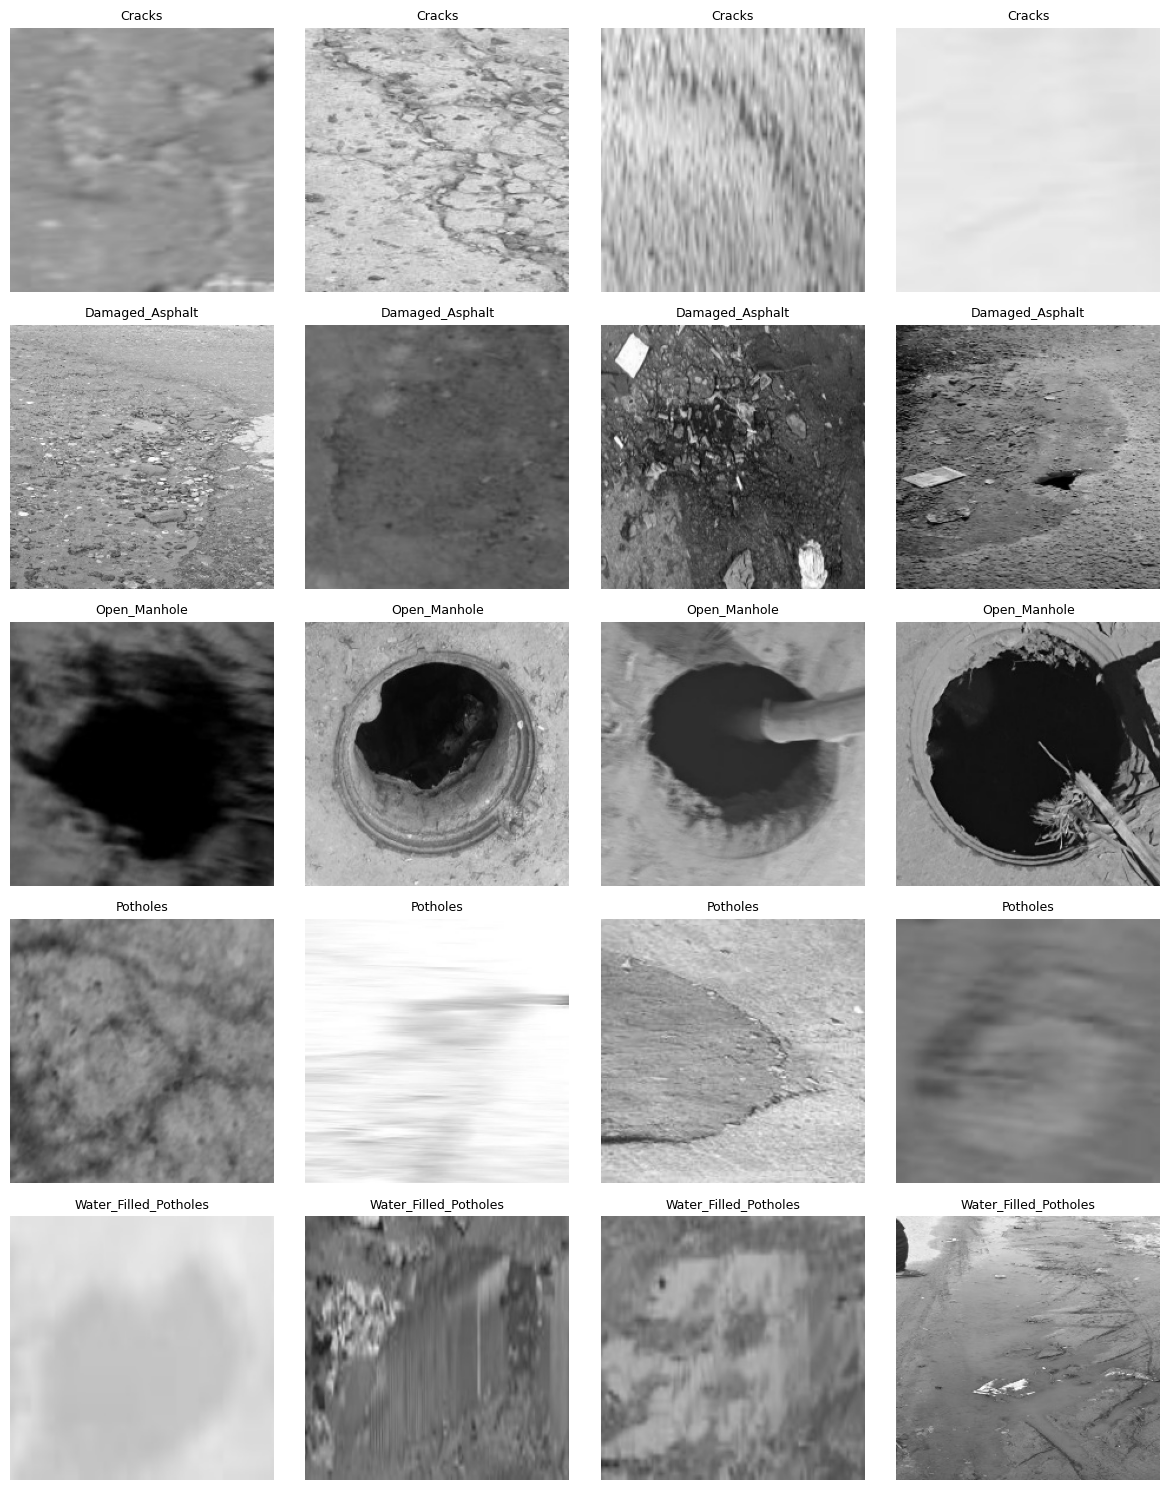

In [35]:
# tampilkan 4 contoh acak dari tiap kelas
daftar_kelas = sorted(os.listdir(DIR_CROP))
np.random.seed(42)
plt.figure(figsize=(12, 15))
for i, kelas in enumerate(daftar_kelas):
    files = os.listdir(DIR_CROP + "/" + kelas)
    pilih = np.random.choice(files, 4, replace=False)
    for j, nama in enumerate(pilih):
        img = cv2.imread(DIR_CROP + "/" + kelas + "/" + nama)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(5, 4, i * 4 + j + 1)
        plt.imshow(img)
        plt.title(kelas, fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

**Hasil:** crop-nya sudah BENER, isinya memang area kerusakan jalan. Semua gambar hitam putih karena dataset ini sudah dibuat grayscale oleh Roboflow. Beberapa gambar terlihat buram, kemungkinan karena foto diambil dari kamera yang bergerak atau bbox-nya kecil lalu diperbesar. Open_Manhole paling gampang dikenali (lubang bundar gelap dengan ring), sedangkan Potholes dan Damaged_Asphalt teksturnya MIRIP, jadi diprediksi bakal sering ketuker.

### C2. Grafik jumlah gambar tiap kelas
Biar kelihatan jelas seberapa timpang jumlah data antar kelas.

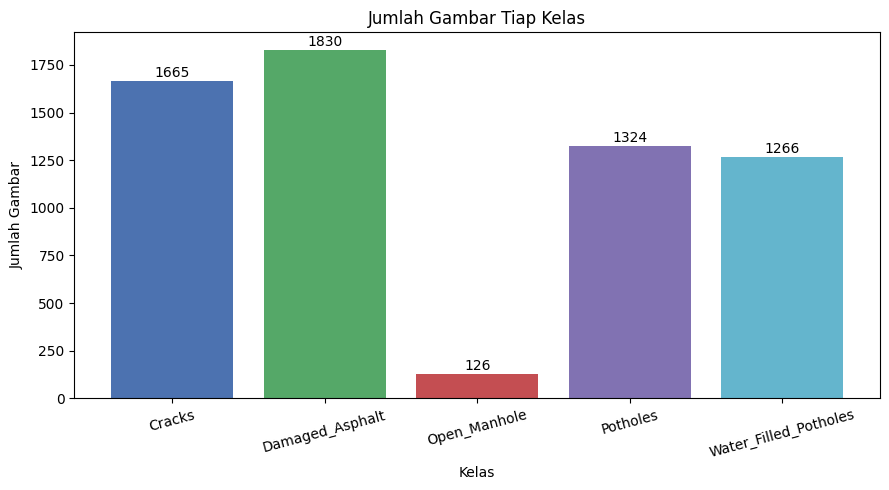

In [36]:
# grafik batang jumlah gambar per kelas
jumlah_kelas = [len(os.listdir(DIR_CROP + "/" + k)) for k in daftar_kelas]
plt.figure(figsize=(9, 5))
bar = plt.bar(daftar_kelas, jumlah_kelas, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#64B5CD"])
for b, n in zip(bar, jumlah_kelas):
    plt.text(b.get_x() + b.get_width() / 2, n + 20, n, ha="center")
plt.title("Jumlah Gambar Tiap Kelas")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Hasil:** total 6.211 gambar dengan distribusi yang TIMPANG. Damaged_Asphalt paling banyak (1.830), Open_Manhole paling sedikit (126), bedanya sekitar 14 kali lipat. Kalau dibiarkan, model bakal cenderung jarang menebak Open_Manhole. Solusinya nanti pakai augmentasi di data latih dan `class_weight` saat training.

## D. Bagi Data dan Augmentasi
Data dibagi jadi train 70%, validation 15%, dan test 15%. Augmentasi cuma dipakai di data train.

### D1. Kumpulkan daftar gambar
Tiap gambar dicatat path, kelas, dan foto asalnya. Satu foto asal bisa punya beberapa versi augmentasi bawaan Roboflow.

In [37]:
# catat path, kelas, dan foto asal tiap gambar
import pandas as pd
data = []
for kelas in daftar_kelas:
    for nama in os.listdir(DIR_CROP + "/" + kelas):
        asal = nama.rsplit("_", 1)[0]
        data.append([DIR_CROP + "/" + kelas + "/" + nama, kelas, asal])

df = pd.DataFrame(data, columns=["path", "kelas", "asal"])
print(len(df), "gambar dari", df["asal"].nunique(), "foto asal")
df.head()

6211 gambar dari 1290 foto asal


,path,kelas,asal
0,/kaggle/working/crop/Cracks/131_jpg_4565.jpg,Cracks,131_jpg
1,/kaggle/working/crop/Cracks/209_jpg_6223.jpg,Cracks,209_jpg
2,/kaggle/working/crop/Cracks/215_jpg_6279.jpg,Cracks,215_jpg
3,/kaggle/working/crop/Cracks/220_jpg_2989.jpg,Cracks,220_jpg
4,/kaggle/working/crop/Cracks/72_jpg_6191.jpg,Cracks,72_jpg


### D2. Bagi data berdasarkan foto asal
Pembagian dilakukan per FOTO ASAL, bukan per gambar. Jadi semua versi dari foto yang sama pasti masuk ke kelompok yang sama. Kalau tidak, model bisa "nyontek" karena pernah lihat versi lain dari foto test saat latihan, akurasinya jadi palsu tinggi (data leakage).

In [38]:
# bagi foto asal jadi train 70%, val 15%, test 15%
asal_unik = df["asal"].unique()
np.random.seed(42)
np.random.shuffle(asal_unik)
n = len(asal_unik)
asal_train = asal_unik[:int(n * 0.7)]
asal_val = asal_unik[int(n * 0.7):int(n * 0.85)]

df["split"] = "test"
df.loc[df["asal"].isin(asal_train), "split"] = "train"
df.loc[df["asal"].isin(asal_val), "split"] = "val"
pd.crosstab(df["kelas"], df["split"], margins=True)

split,test,train,val,All
kelas,,,,
Cracks,188,1165,312,1665
Damaged_Asphalt,254,1298,278,1830
Open_Manhole,20,86,20,126
Potholes,198,940,186,1324
Water_Filled_Potholes,196,850,220,1266
All,856,4339,1016,6211


**Hasil:** 6.211 gambar ternyata berasal dari cuma 1.290 foto asal, rata-rata hampir 5 gambar per foto. Ini MEMBUKTIKAN banyak gambar yang "kembar" (versi augmentasi Roboflow dan beberapa objek dalam 1 foto), jadi pembagian per foto asal memang WAJIB.

| Bagian | Jumlah | Persen |
|---|---|---|
| Train | 4.339 | 69,9% |
| Validation | 1.016 | 16,4% |
| Test | 856 | 13,8% |

Persentasenya sedikit meleset dari 70/15/15 karena jumlah gambar tiap foto asal beda-beda, tapi masih wajar. Open_Manhole kebagian 86 / 20 / 20, cukup untuk dievaluasi.

### D3. Pipeline data dengan tf.data
Gambar dibaca dengan `tf.io.decode_image`, lalu disusun jadi batch 32. Pakai `cache` dan `prefetch` supaya GPU gak nganggur nunggu CPU baca file. Data train diacak (`shuffle`), val dan test enggak.

Nilai piksel SENGAJA dibiarkan 0 sampai 255, karena normalisasinya nanti ikut di dalam model, menyesuaikan aturan yang dipakai ResNet18 waktu dilatih di ImageNet.

In [39]:
# pipeline tf.data untuk train, val, test
IMG_SIZE = 224
BATCH = 32
kelas_ke_angka = {k: i for i, k in enumerate(daftar_kelas)}

def baca_gambar(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def buat_dataset(bagian, acak=False):
    d = df[df["split"] == bagian]
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["kelas"].map(kelas_ke_angka).values))
    ds = ds.map(baca_gambar, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if acak:
        ds = ds.shuffle(1000, seed=42)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = buat_dataset("train", acak=True)
val_ds = buat_dataset("val")
test_ds = buat_dataset("test")
print(kelas_ke_angka)
print(train_ds.element_spec)

{'Cracks': 0, 'Damaged_Asphalt': 1, 'Open_Manhole': 2, 'Potholes': 3, 'Water_Filled_Potholes': 4}
(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


**Hasil:** label kelas diubah jadi angka 0 sampai 4. Tiap batch berbentuk (32, 224, 224, 3) dengan label berupa angka bulat. GPU Tesla T4 juga sudah terdeteksi dan siap dipakai.

### D4. Lapisan augmentasi
Augmentasi yang dipakai: flip horizontal dan vertikal, rotasi kecil, zoom, dan kontras. Semuanya masuk akal untuk foto jalan, karena kerusakan jalan bisa difoto dari arah mana aja. Lapisan ini cuma AKTIF saat training, saat evaluasi otomatis mati.

In [40]:
# lapisan augmentasi, cuma aktif waktu training
augmentasi = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.2),
], name="augmentasi")

### D5. Contoh hasil augmentasi dari 5 kelas
Kolom pertama gambar asli, 3 kolom berikutnya hasil augmentasi acak dari gambar yang sama.

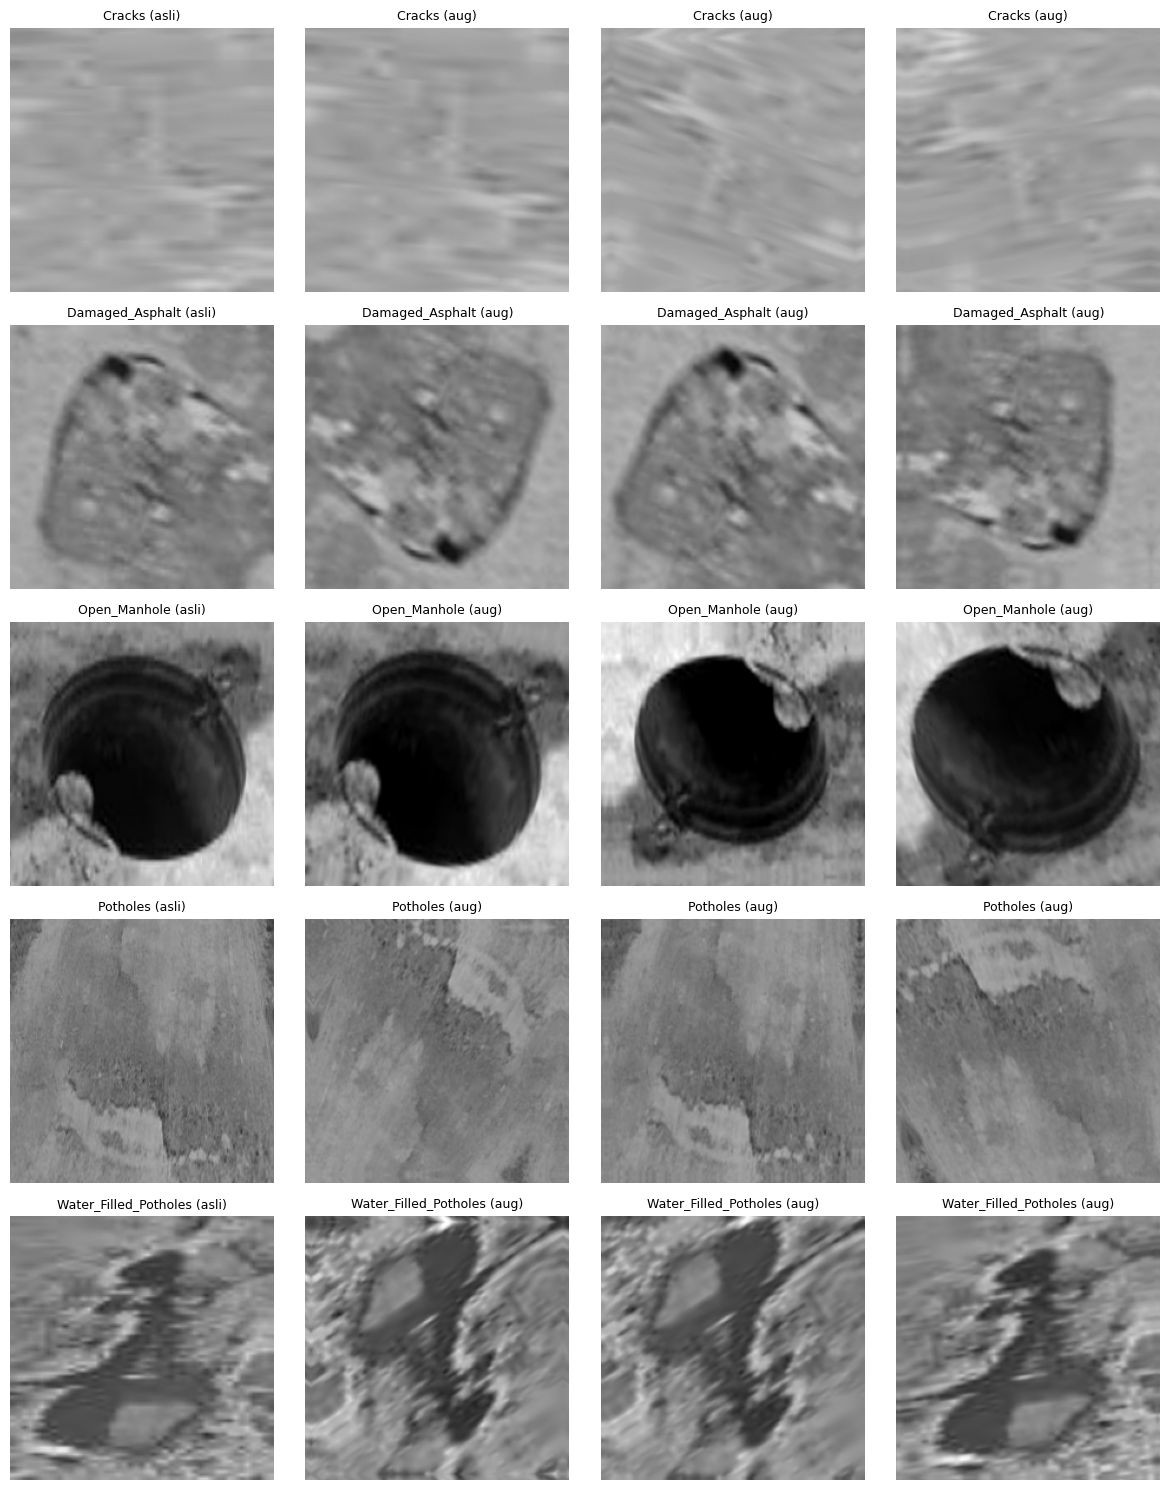

In [41]:
# 1 gambar asli + 3 hasil augmentasi tiap kelas
plt.figure(figsize=(12, 15))
for i, kelas in enumerate(daftar_kelas):
    path = df[(df["kelas"] == kelas) & (df["split"] == "train")]["path"].iloc[0]
    img, _ = baca_gambar(path, 0)
    plt.subplot(5, 4, i * 4 + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(kelas + " (asli)", fontsize=9)
    plt.axis("off")
    for j in range(3):
        aug = augmentasi(tf.expand_dims(img, 0), training=True)[0]
        plt.subplot(5, 4, i * 4 + j + 2)
        plt.imshow(aug.numpy().clip(0, 255).astype("uint8"))
        plt.title(kelas + " (aug)", fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

**Hasil:** augmentasi bikin variasi posisi, arah, dan kontras, tapi bentuk kerusakannya TETAP jelas. Jadi augmentasi ini aman dipakai, gak sampai mengubah arti gambar. Efeknya model dipaksa belajar bentuk kerusakan, bukan hafalan posisi atau arahnya.

In [42]:
# cek versi keras dan keras_hub
import keras
print("Keras", keras.__version__)
try:
    import keras_hub
    print("keras_hub", keras_hub.__version__)
except ImportError:
    print("keras_hub belum ada")

Keras 3.13.2
keras_hub 0.26.0


## E. Model ResNet18 (Transfer Learning)
ResNet18 punya 18 lapisan dengan "jalan pintas" (skip connection) yang bikin jaringannya gampang dilatih walaupun dalam. Model ini dipilih karena ringan (sekitar 11 juta parameter) dan sesuai dengan materi Modul 6.

TensorFlow tidak menyediakan ResNet18 di `tf.keras.applications` (cuma ada ResNet50 ke atas), jadi ResNet18 diambil dari library `keras_hub` lengkap dengan bobot pretrained ImageNet.

### E1. Muat backbone ResNet18
Dimuat tanpa lapisan klasifikasi bawaan, jadi yang tersisa cuma bagian pengekstrak fitur. Dicek jumlah parameter dan bentuk output-nya.

In [43]:
# muat ResNet18 pretrained imagenet dari keras_hub
import keras_hub
resnet18 = keras_hub.models.ResNetBackbone.from_preset("resnet_18_imagenet")
print("jumlah parameter:", resnet18.count_params())
print("bentuk output:", resnet18(tf.zeros((1, 224, 224, 3))).shape)

jumlah parameter: 11186112
bentuk output: (1, 7, 7, 512)


### E2. Hitung class_weight
Karena datanya timpang, tiap kelas dikasih bobot. Kelas yang datanya SEDIKIT (Open_Manhole) dapat bobot lebih BESAR, jadi kesalahan di kelas itu "dihukum" lebih berat saat training.

Bobotnya DILUNAKKAN pakai akar kuadrat. Di percobaan pertama bobot Open_Manhole sampai 10 kali lipat, dan itu bikin training goyang parah. Dengan akar kuadrat, bobotnya jadi sekitar 3, kelas kecil tetap diperhatikan tapi gak sampai bikin model panik.

In [44]:
# bobot kelas dari data train, dilunakkan pakai akar kuadrat
jumlah_train = df[df["split"] == "train"]["kelas"].value_counts()
total = jumlah_train.sum()
class_weight = {}
for kelas, idx in kelas_ke_angka.items():
    class_weight[idx] = np.sqrt(total / (len(daftar_kelas) * jumlah_train[kelas]))
    print(f"{kelas:22s} {jumlah_train[kelas]:5d} gambar -> bobot {class_weight[idx]:.2f}")

Cracks                  1165 gambar -> bobot 0.86
Damaged_Asphalt         1298 gambar -> bobot 0.82
Open_Manhole              86 gambar -> bobot 3.18
Potholes                 940 gambar -> bobot 0.96
Water_Filled_Potholes    850 gambar -> bobot 1.01


**Hasil:** setelah dilunakkan pakai akar kuadrat, bobot Open_Manhole jadi sekitar 3,18, sedangkan kelas besar seperti Damaged_Asphalt sekitar 0,82. Kelas kecil tetap diperhatikan, tapi gak sampai bikin model "panik".

### E3. Susun model ResNet18
Urutan lapisannya:
1. **Augmentasi** (cuma aktif saat training)
2. **Normalisasi** piksel ke 0 sampai 1, lalu disesuaikan dengan rata-rata dan simpangan ImageNet, karena ResNet18 dulu dilatih dengan aturan itu
3. **ResNet18 dibekukan** (`trainable = False`), jadi fitur yang sudah dipelajari dari ImageNet gak rusak
4. **Head baru:** GlobalAveragePooling2D, Dense 256, Dropout 0.3, lalu Dense 5 dengan softmax untuk 5 kelas

In [45]:
# susun ResNet18 beku + head klasifikasi 5 kelas
resnet18.trainable = False
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentasi(inputs)
x = tf.keras.layers.Rescaling(1. / 255)(x)
x = tf.keras.layers.Normalization(mean=[0.485, 0.456, 0.406], variance=[0.229**2, 0.224**2, 0.225**2])(x)
x = resnet18(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(daftar_kelas), activation="softmax")(x)

model_resnet = tf.keras.Model(inputs, outputs, name="resnet18")
model_resnet.summary()

Model: "resnet18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_1 (Normalization) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ res_net_backbone                │ (None, 7, 7, 512)      │    11,186,112 │
│ (ResNetBackbone)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,318,725 (43.18 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 11,186,112 (42.67 MB)

**Hasil:** total 11.318.725 parameter, tapi yang DILATIH cuma 132.613 (sekitar 1,2%), yaitu bagian head-nya aja. Sisanya 11.186.112 parameter milik ResNet18 dibekukan. Ini bikin training CEPAT dan gak gampang overfitting, karena model cukup belajar "menerjemahkan" fitur ImageNet ke 5 kelas kerusakan jalan.

### E4. Latih ResNet18
Pakai optimizer Adam dan loss `sparse_categorical_crossentropy` (karena labelnya angka 0 sampai 4, bukan one-hot). Callback `EarlyStopping` memantau `val_loss`: kalau 3 epoch berturut-turut GAK membaik, training berhenti dan bobot terbaik dikembalikan. Waktu training juga dicatat.

In [46]:
# compile lalu latih fase beku, early stopping dibuat baru
import time
model_resnet.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"])

mulai = time.time()
history_resnet = model_resnet.fit(train_ds, validation_data=val_ds, epochs=30,
                                  class_weight=class_weight,
                                  callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
waktu_resnet = time.time() - mulai
print(f"waktu training ResNet18: {waktu_resnet / 60:.1f} menit")

Epoch 1/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.6151 - loss: 1.1623 - val_accuracy: 0.2441 - val_loss: 1.6474
Epoch 2/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.5642 - loss: 1.0429 - val_accuracy: 0.3219 - val_loss: 1.5237
Epoch 3/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.5826 - loss: 1.0003 - val_accuracy: 0.3406 - val_loss: 1.4438
Epoch 4/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.5895 - loss: 0.9578 - val_accuracy: 0.3573 - val_loss: 1.4365
Epoch 5/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.5771 - loss: 0.9565 - val_accuracy: 0.3691 - val_loss: 1.3976
Epoch 6/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.5856 - loss: 0.9651 - val_accuracy: 0.3543 - val_loss: 1.3941
Epoch 7/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.5801 - loss: 0.9205 - val_accuracy: 0.3740 - val_loss: 1.3954
Epoch 8/30
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.5976 - loss: 0.9557 - val_acc

**Hasil:** fase beku berhenti di epoch 13 (EarlyStopping) dalam 1,7 menit, bobot terbaik dari epoch 10 dengan val_accuracy sekitar 41% dan val_loss 1,29. Ini UNDERFITTING: fitur ImageNet dipelajari dari foto berwarna benda sehari-hari, sedangkan data kita hitam putih berisi TEKSTUR aspal, jadi kalau backbone dikunci total fiturnya kurang cocok.

Aturan normalisasi sudah dicek SAMA dengan bawaan preset ResNet18 di keras_hub, jadi masalahnya bukan di situ. Makanya lanjut ke fine-tuning.

Catatan: angka "accuracy" di log train ikut dibobot class_weight dan dihitung saat augmentasi aktif, jadi gak bisa dibandingkan langsung dengan val_accuracy.

### E5. Fine-tuning: buka kunci lapisan atas
Separuh lapisan ATAS ResNet18 dibuka kuncinya, separuh bawah tetap dibekukan. Lapisan bawah mengenali fitur dasar (garis, tepi) yang tetap berguna, sedangkan lapisan atas mengenali fitur rumit yang perlu disesuaikan dengan tekstur kerusakan jalan.

Lapisan BatchNormalization di separuh atas IKUT dibuka. Dari percobaan sebelumnya, waktu BN dikunci val_accuracy cuma sekitar 45 sampai 57%, sedangkan waktu BN ikut dibuka bisa sekitar 60%. Artinya BN perlu ikut menyesuaikan diri dengan data kita yang hitam putih dan isinya tekstur aspal, beda jauh dari foto ImageNet.

In [47]:
# buka kunci separuh atas ResNet18, BatchNormalization ikut dibuka
resnet18.trainable = True
batas = len(resnet18.layers) // 2
for layer in resnet18.layers[:batas]:
    layer.trainable = False

dilatih = sum(tf.size(w).numpy() for w in model_resnet.trainable_weights)
print("total lapisan ResNet18:", len(resnet18.layers), "| dibuka mulai lapisan ke:", batas)
print("parameter yang dilatih sekarang:", dilatih)

total lapisan ResNet18: 72 | dibuka mulai lapisan ke: 36
parameter yang dilatih sekarang: 10626053


**Hasil:** 36 dari 72 lapisan ResNet18 dibuka, total 10.626.053 parameter ikut dilatih (sekitar 94% dari seluruh model).

### E6. Latih ulang dengan learning rate kecil
Learning rate diturunkan jadi 0,00001 (100 kali lebih kecil dari fase beku) supaya bobot ImageNet cuma "disetel halus", bukan dirombak total. Di percobaan awal pakai 0,0001 dan hasilnya naik turun gak stabil.

Jatah fine-tuning maksimal 40 epoch. Di percobaan sebelumnya dengan 20 epoch, val_loss masih turun sampai epoch terakhir, artinya training-nya "kepotong" sebelum mentok. EarlyStopping tetap menjaga, jadi kalau sudah gak membaik training berhenti sendiri.

Patience EarlyStopping di fase ini dinaikkan jadi 5. Dengan learning rate sekecil ini val_loss naiknya pelan dan kadang naik turun sedikit, jadi patience 3 bisa menghentikan training terlalu cepat.


In [48]:
# fine-tuning lanjut dari epoch terakhir, learning rate 0.00001, jatah 40 epoch, patience 5
model_resnet.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"])

mulai = time.time()
history_resnet_ft = model_resnet.fit(train_ds, validation_data=val_ds,
                                     epochs=len(history_resnet.epoch) + 40,
                                     initial_epoch=len(history_resnet.epoch),
                                     class_weight=class_weight,
                                     callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
waktu_resnet += time.time() - mulai
print(f"waktu training total ResNet18: {waktu_resnet / 60:.1f} menit")

Epoch 14/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 20s 98ms/step - accuracy: 0.2180 - loss: 2.3669 - val_accuracy: 0.2874 - val_loss: 1.8136
Epoch 15/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.2367 - loss: 2.0931 - val_accuracy: 0.3169 - val_loss: 1.6767
Epoch 16/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.2519 - loss: 1.8447 - val_accuracy: 0.3514 - val_loss: 1.5187
Epoch 17/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.2680 - loss: 1.6866 - val_accuracy: 0.3858 - val_loss: 1.4012
Epoch 18/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.2945 - loss: 1.5444 - val_accuracy: 0.4262 - val_loss: 1.3193
Epoch 19/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.3033 - loss: 1.4529 - val_accuracy: 0.4557 - val_loss: 1.2576
Epoch 20/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.3376 - loss: 1.3657 - val_accuracy: 0.4872 - val_loss: 1.2082
Epoch 21/53
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.3570 - loss: 1

**Hasil:** fine-tuning BERHASIL menaikkan performa. Val accuracy naik dari sekitar 46% jadi sekitar 60%, dan val_loss turun dari 1,21 jadi 0,906 (bobot terbaik di epoch 30). Di epoch 21 akurasi sempat anjlok karena model "kaget" saat kunci lapisan dibuka, lalu pulih dan naik terus. Train dan val accuracy hampir sejajar, jadi belum overfitting. Total waktu training ResNet18: 5,6 menit.

### E6b. Lanjutan fine-tuning
Sampai epoch 53, val_loss MASIH turun, jadi training dilanjutkan maksimal 40 epoch lagi dengan pengaturan yang sama. Riwayat training-nya disambung ke riwayat E6 supaya grafiknya tetap utuh.

In [50]:
# lanjutkan fine-tuning 40 epoch lagi lalu sambung riwayatnya
mulai = time.time()
lanjutan = model_resnet.fit(train_ds, validation_data=val_ds,
                            epochs=len(history_resnet.epoch) + len(history_resnet_ft.epoch) + 40,
                            initial_epoch=len(history_resnet.epoch) + len(history_resnet_ft.epoch),
                            class_weight=class_weight,
                            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
waktu_resnet += time.time() - mulai

for k in history_resnet_ft.history:
    history_resnet_ft.history[k] += lanjutan.history[k]
print(f"waktu training total ResNet18: {waktu_resnet / 60:.1f} menit")

Epoch 54/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.5561 - loss: 0.9350 - val_accuracy: 0.6220 - val_loss: 0.8987
Epoch 55/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step - accuracy: 0.5580 - loss: 0.9344 - val_accuracy: 0.6220 - val_loss: 0.9047
Epoch 56/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.5693 - loss: 0.9058 - val_accuracy: 0.6299 - val_loss: 0.8855
Epoch 57/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.5642 - loss: 0.9158 - val_accuracy: 0.6240 - val_loss: 0.8802
Epoch 58/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.5732 - loss: 0.9078 - val_accuracy: 0.6220 - val_loss: 0.8836
Epoch 59/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.5815 - loss: 0.8879 - val_accuracy: 0.6191 - val_loss: 0.8874
Epoch 60/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step - accuracy: 0.5905 - loss: 0.8900 - val_accuracy: 0.6230 - val_loss: 0.8820
Epoch 61/93
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 91ms/step - accuracy: 0.5891 - loss: 0

**Hasil:** di awal fine-tuning (epoch 14) model sempat "KAGET", train accuracy anjlok dan loss melonjak, karena BatchNormalization mulai menyesuaikan diri dengan data baru. Setelah itu naiknya MULUS: val_accuracy naik dari 29% jadi 62,5% di epoch 53, dan val_loss masih turun saat jatah 40 epoch habis.

Training dilanjutkan di E6b, tapi kali ini model sudah MENTOK: val_accuracy cuma muter di 62 sampai 63%. Bobot terbaik di epoch 57 (val_loss 0,880), lalu EarlyStopping berhenti di epoch 62. Artinya ResNet18 sudah mencapai batas kemampuannya untuk data ini. Total waktu training 12,2 menit.

### E7. Grafik histori ResNet18
Grafik akurasi dan loss dari fase 1 (backbone dibekukan) dan fase 2 (fine-tuning) disambung jadi satu. Garis putus-putus menandai titik mulai fine-tuning.

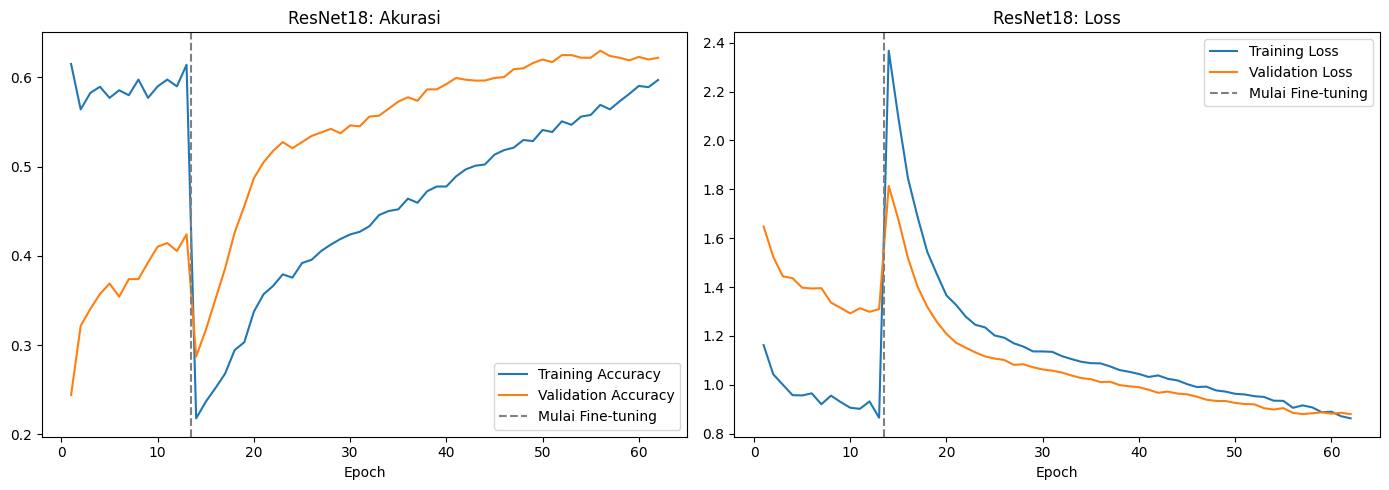

In [51]:
# fungsi grafik histori akurasi dan loss dua fase
def plot_histori(h1, h2, judul):
    acc = h1.history["accuracy"] + h2.history["accuracy"]
    val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
    loss = h1.history["loss"] + h2.history["loss"]
    val_loss = h1.history["val_loss"] + h2.history["val_loss"]
    epoch = range(1, len(acc) + 1)
    batas_ft = len(h1.history["accuracy"]) + 0.5

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epoch, acc, label="Training Accuracy")
    plt.plot(epoch, val_acc, label="Validation Accuracy")
    plt.axvline(batas_ft, color="gray", linestyle="--", label="Mulai Fine-tuning")
    plt.title(judul + ": Akurasi")
    plt.xlabel("Epoch")
    plt.legend(loc="lower right")

    plt.subplot(1, 2, 2)
    plt.plot(epoch, loss, label="Training Loss")
    plt.plot(epoch, val_loss, label="Validation Loss")
    plt.axvline(batas_ft, color="gray", linestyle="--", label="Mulai Fine-tuning")
    plt.title(judul + ": Loss")
    plt.xlabel("Epoch")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_histori(history_resnet, history_resnet_ft, "ResNet18")

**Hasil:** grafik menunjukkan DUA fase yang jelas:

1. **Fase beku (epoch 1 sampai 13):** val loss tertahan jauh di atas train loss dan val accuracy mentok di sekitar 41%. Model gak bisa berkembang karena fitur ImageNet yang dikunci kurang cocok dengan tekstur aspal hitam putih.
2. **Fase fine-tuning (epoch 14 sampai 62):** di awal model sempat KAGET (train loss melonjak sampai 2,4) karena BatchNormalization mulai menyesuaikan diri. Setelah itu kedua loss turun MULUS bersamaan dan val accuracy naik sampai sekitar 62%.

Di akhir training, train loss dan val loss ketemu di angka yang hampir sama (sekitar 0,88), jadi model TIDAK overfitting. Val accuracy terlihat lebih tinggi dari train accuracy karena train accuracy dihitung saat augmentasi dan dropout aktif plus dibobot class_weight, jadi soal latihannya memang "lebih susah". Setelah epoch 57 grafiknya mendatar, tanda model sudah mencapai batasnya, dan EarlyStopping menghentikan training di epoch 62.

## F. Evaluasi
Model diuji di data TEST, yaitu data yang sama sekali belum pernah dilihat saat training maupun validasi. Hasilnya ditampilkan lewat confusion matrix dan classification report (precision, recall, F1 per kelas).

Yang paling diperhatikan adalah **F1 macro**, yaitu rata-rata F1 dari 5 kelas dengan bobot SAMA. Ini lebih adil dari akurasi biasa karena datanya timpang: kalau pakai akurasi biasa, kelas besar kayak Damaged_Asphalt bakal mendominasi nilai.

### F1. Siapkan label asli dan fungsi evaluasi

In [52]:
# label asli data test dan fungsi evaluasi
import seaborn as sns
from sklearn.metrics import classification_report

y_true = np.concatenate([y.numpy() for _, y in test_ds])

def evaluasi(model, judul):
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    cm = tf.math.confusion_matrix(y_true, y_pred).numpy()
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=daftar_kelas, yticklabels=daftar_kelas)
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix " + judul)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, target_names=daftar_kelas, digits=3))
    return y_pred

### F2. Confusion matrix dan classification report ResNet18
Baris = kelas asli, kolom = tebakan model. Angka di diagonal adalah tebakan yang BENAR, angka di luar diagonal adalah kelas yang ketuker.

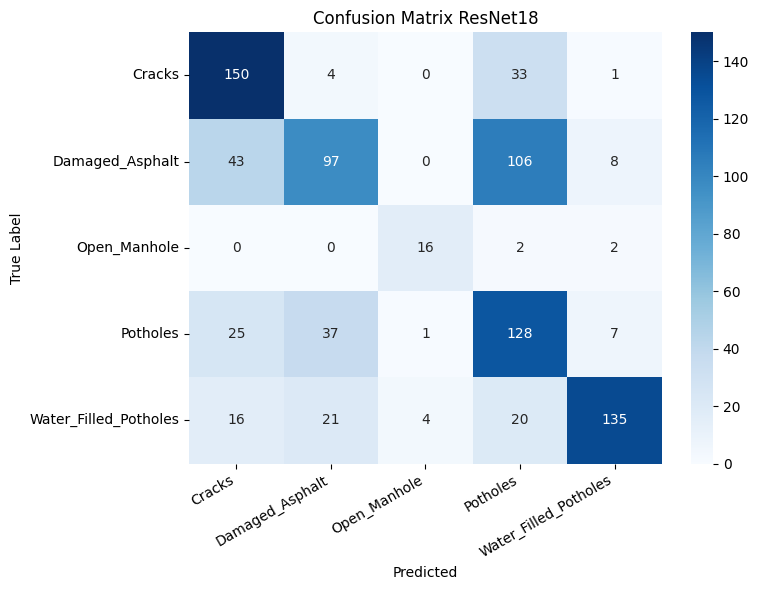

                       precision    recall  f1-score   support

               Cracks      0.641     0.798     0.711       188
      Damaged_Asphalt      0.610     0.382     0.470       254
         Open_Manhole      0.762     0.800     0.780        20
             Potholes      0.443     0.646     0.526       198
Water_Filled_Potholes      0.882     0.689     0.774       196

             accuracy                          0.614       856
            macro avg      0.668     0.663     0.652       856
         weighted avg      0.644     0.614     0.612       856



In [53]:
# evaluasi ResNet18 di data test
pred_resnet = evaluasi(model_resnet, "ResNet18")

**Hasil:** di data test, akurasi 61,4% dan F1 macro 0,652. Angka ini MIRIP dengan val accuracy saat training (sekitar 62%), jadi modelnya konsisten dan gak overfitting.

| Kelas | F1 | Keterangan |
|---|---|---|
| Open_Manhole | 0,780 | Paling bagus, 16 dari 20 benar |
| Water_Filled_Potholes | 0,774 | Precision tertinggi (0,882) |
| Cracks | 0,711 | Recall tinggi (0,798) |
| Potholes | 0,526 | Sering jadi "tempat buangan" tebakan |
| Damaged_Asphalt | 0,470 | Paling jelek, recall cuma 0,382 |

Temuan penting:
1. **Damaged_Asphalt dan Potholes SALING KETUKER parah.** Ada 106 gambar Damaged_Asphalt yang ditebak Potholes, dan 37 Potholes ditebak Damaged_Asphalt. Wajar, karena dua-duanya aspal rusak yang berlubang, bedanya cuma di kedalaman dan bentuk, yang susah dilihat di gambar hitam putih yang buram.
2. **Open_Manhole justru BAGUS** walaupun datanya paling sedikit (cuma 86 gambar latih). Ini bukti class_weight bekerja, ditambah bentuknya memang KHAS (lubang bundar gelap dengan ring).
3. **Water_Filled_Potholes cukup mudah dikenali**, kemungkinan karena permukaan air terlihat rata dan memantulkan cahaya, beda dengan tekstur aspal.
4. **Cracks** cukup bagus, tapi 33 gambar ditebak Potholes, kemungkinan retak yang lebar mirip lubang dangkal.

## G. Kesimpulan

Model **ResNet18 dengan Transfer Learning** berhasil mengklasifikasi 5 jenis kerusakan jalan dengan **akurasi 61,4%** dan **F1 macro 0,652** di data test. Angkanya memang belum tinggi, tapi jauh di atas tebakan acak (20% untuk 5 kelas) dan konsisten antara data validasi dan test.

**Yang dilakukan:**
1. Crop 6.211 objek kerusakan dari foto jalan utuh berdasarkan bbox COCO, dengan margin 15% supaya pinggiran kerusakan ikut terlihat.
2. Data dibagi per FOTO ASAL (bukan per gambar) supaya gak ada kebocoran data, karena 6.211 gambar ternyata cuma berasal dari 1.290 foto.
3. Augmentasi (flip, rotasi, zoom, kontras) dan class_weight akar kuadrat untuk mengatasi data yang TIMPANG.
4. Training dua fase: backbone dibekukan dulu, lalu fine-tuning separuh lapisan atas dengan learning rate kecil. Fine-tuning menaikkan val accuracy dari sekitar 41% jadi 62%.
5. EarlyStopping menghentikan training saat model sudah mentok, dan grafik histori menunjukkan model TIDAK overfitting.

**Kenapa hasilnya belum maksimal:**
- Dataset sudah dibuat **hitam putih** oleh Roboflow, jadi model gak bisa memanfaatkan warna.
- Banyak gambar **buram**, kemungkinan dari kamera yang bergerak.
- Damaged_Asphalt dan Potholes memang **MIRIP secara visual**, dan inilah sumber kesalahan terbesar.

**Kenapa tidak jadi membandingkan dua model:**

Awalnya notebook ini direncanakan membandingkan ResNet18 dengan MobileNetV2. MobileNetV2 sudah dicoba dengan resep training yang SAMA, tapi hasilnya gak stabil: setiap kali fine-tuning, val_loss malah memburuk dan val_accuracy cuma sekitar 40%, bahkan sempat anjlok sampai model cuma menebak satu kelas. Penyebabnya kemungkinan MobileNetV2 lebih SENSITIF terhadap BatchNormalization dan learning rate, karena modelnya ringan dan punya BatchNormalization di hampir setiap lapisan.

Perbandingan yang adil butuh resep training yang sama untuk dua model. Kalau MobileNetV2 dikutak-katik terus sampai bagus, perbandingannya jadi gak adil lagi. Jadi diputuskan FOKUS ke ResNet18 saja, karena modelnya stabil, sesuai materi Modul 6, dan kriteria tugas memang cuma meminta satu model (CNN custom ATAU ResNet18 ATAU MobileNetV2).

**Pelajaran dari proses training:**
- EarlyStopping harus dibuat BARU di setiap training. Kalau dipakai ulang, di Keras 3 dia masih ingat nilai terbaik dari training sebelumnya.
- Learning rate fine-tuning yang terlalu besar dan class_weight yang terlalu ekstrem bikin training goyang, jadi keduanya perlu dikecilkan.

**Saran pengembangan:**
- Pakai data BERWARNA dan lebih tajam, terutama untuk membedakan Damaged_Asphalt dan Potholes.
- Tambah data Open_Manhole yang masih sangat sedikit.
- Untuk dipakai di foto jalan utuh, model ini perlu digabung dengan model deteksi objek, karena model klasifikasi butuh input yang sudah di-crop ke area kerusakannya.